In [7]:
import os
import sys

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.integrate import simpson

from agnspec import io, preprocessing as prep, plotting
from agnspec.utils import C_KMS, LINE_WAVELENGTHS
from agnspec.continuum import PowerLaw
from agnspec.emission_lines import OIIIComplex
from agnspec.fitting import LeastSquares
from agnspec.models import AGNModel
from agnspec.balmer import BalmerPseudoContinuum, EDGE_VAC
from agnspec.optical_region import OpticalRegionModel, load_park2022_feii
from my_utils import get_ebv
plt.show()
%matplotlib inline


In [3]:
FLUX_UNIT = r"10$^{-17}$ erg s$^{-1}$ cm$^{-2}$ $\mathrm{\AA}^{-1}$"

In [4]:
# ----------------------------------------------------------------------
# configuration (all rest-frame, vacuum Angstrom)
# ----------------------------------------------------------------------
# Fitting windows of KPK13 Sect. 2: 2650-2670, 3020-3040, "Balmer edge
# at 3646" and everything redward of 4000 A that has been cleaned.
# The width of the edge window is not given in the paper -> my choice.
UV_WINDOWS = [(2650.0, 2670.0), (3020.0, 3040.0)]
EDGE_WINDOW = (3610.0, 3680.0)
RED_WINDOW = (4000.0, 5700.0)      # upper limit: my choice (data end ~5790)
STAGE1_RANGE = (4000.0, 5500.0)    # paper: 4000-5500 A
PL_PIVOT = 5600.0                  # paper: F_pl = F_5600 (l/5600)^alpha

Z_FALLBACK = None


## 1) Load data and do preliminary cleaning.

In [5]:
fname = '../spSpec-52724-1195-098.fit'
outdir = '.'

spSpec-52724-1195-098.fit: z = 0.588403, E(B-V)_SFD = 0.0406, 3858 pixels, 3794-9221 A (obs)
rest-frame range: 2389-5789 A


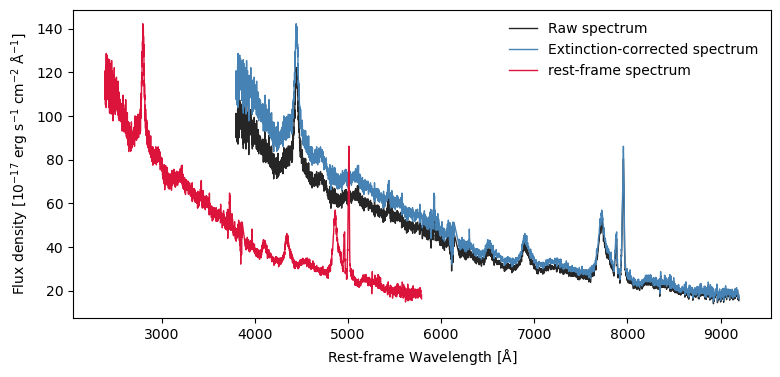

In [10]:
wave_obs, flux_obs, err_obs, hdr = io.read_spectrum(fname)
z = float(hdr["Z"])
src_ra, src_dec = hdr['RA'], hdr['DEC']
ebv = get_ebv(src_ra, src_dec)  # Schlegel+98 E(B-V) from IRSA dust maps
#ebv = float(hdr["SFD_EBV"])  # Schlegel+98 E(B-V) stored in the file
print(f"{os.path.basename(fname)}: z = {z:.6f}, E(B-V)_SFD = {ebv:.4f}, "
  f"{len(wave_obs)} pixels, {wave_obs[0]:.0f}-{wave_obs[-1]:.0f} A (obs)")

# Bad pixels: spSpec marks them with error <= 0
good = prep.mask_bad_pixels(wave_obs, flux_obs, err_obs)
wave_obs, flux_obs, err_obs = wave_obs[good], flux_obs[good], err_obs[good]

# CCM89, R_V = 3.1, applied at OBSERVED wavelengths, flux AND error
flux_dr, err_dr = prep.deredden_spectrum(wave_obs, flux_obs, error=err_obs,
 ebv=ebv, rv=3.1, law="ccm89")
# Rest frame: wavelength only. Flux density and error are NOT touched.
wave = prep.to_rest_frame(wave_obs, z)
flux, err = flux_dr, err_dr
print(f"rest-frame range: {wave[0]:.0f}-{wave[-1]:.0f} A")

fig, ax = plt.subplots(figsize=(9, 4))
plotting.plot_spectrum(wave_obs, flux_obs, ax=ax, stage="raw", flux_unit=FLUX_UNIT)
plotting.plot_spectrum(wave_obs, flux_dr, ax=ax, stage="dered", flux_unit=FLUX_UNIT)
plotting.plot_spectrum(wave, flux, ax=ax, stage="rest", flux_unit=FLUX_UNIT)

fig.savefig(os.path.join(outdir, "00_preprocessing.png"), dpi=130, bbox_inches="tight")


### 2) stage 1: Fit O[III] lines to get narrow line region kinematics.

In [11]:
import sys
sys.path.append('/home/ashwanipandey/new_research/KIAA/GalSpec')
import galspec
from astropy.modeling import models, fitting

In [ ]:
# From Greene & Ho (2005, ApJ, 630, 122); The first window is to include Ca II K&H.
cont_windows = [[3900, 4060], [4170, 4260], [4430, 4770], [5080, 5550], [6050, 6200], [6890, 7010]]  

fig, ax = plt.subplots(1, 1, figsize=(15, 5))
ax.step(wave, gaussian_filter1d(flux, 2), where='mid', color='k', label='Dereddened Flux')
for window in cont_windows:
    ax.axvspan(window[0], window[1], color='C1', alpha=0.5)
ax.set_xlabel(r'Rest Wavelength (Å)', fontsize=14)
ax.set_ylabel(f'Flux ({units})', fontsize=14)
ax.minorticks_on()
ax.set_ylim(0, 70)
ax.legend(loc='upper left', fontsize=14)
plt.show()